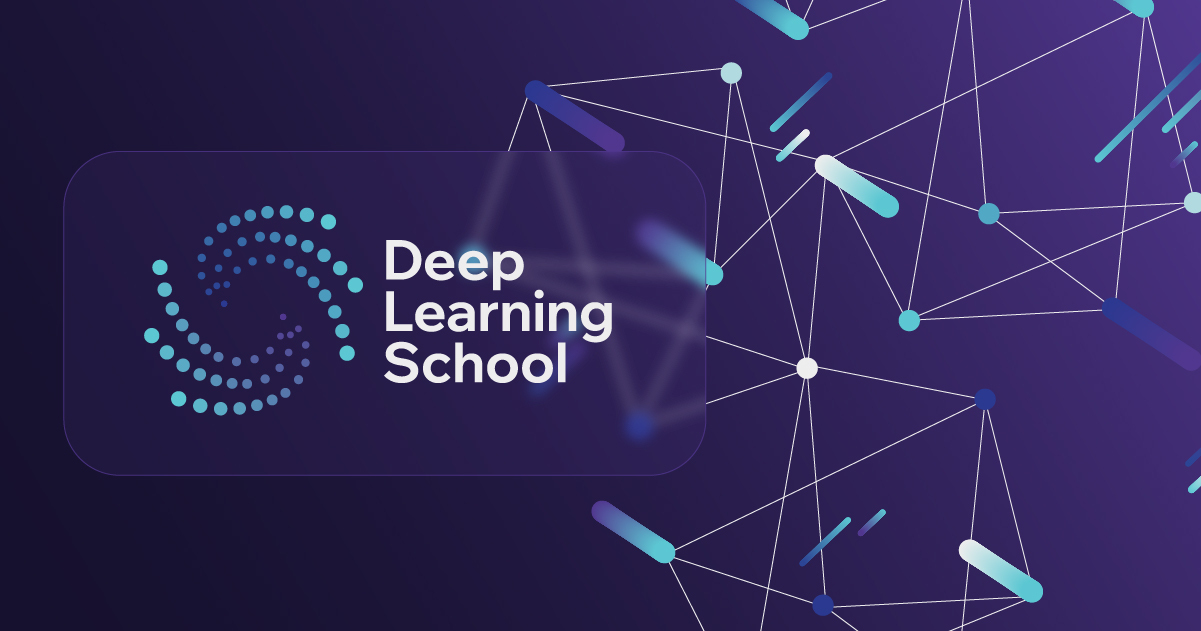

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание. Обучение языковой модели с помощью LSTM </b></h1>


В этом задании Вам предстоит обучить языковую модель с помощью рекуррентной нейронной сети. В отличие от семинарского занятия, Вам необходимо будет работать с отдельными словами, а не буквами.


Установим модуль ```datasets```, чтобы нам проще было работать с данными.

In [1]:
!pip install dataset

Импорт необходимых библиотек

In [2]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler

import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from datasets import load_dataset
from nltk.tokenize import sent_tokenize, word_tokenize
from sklearn.model_selection import train_test_split
import nltk

from collections import Counter
from typing import List

import seaborn
seaborn.set(palette='summer')

import gc

In [3]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /usr/share/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

## Подготовка данных

Воспользуемся датасетом imdb. В нем хранятся отзывы о фильмах с сайта imdb. Загрузим данные с помощью функции ```load_dataset```

In [5]:
# Загрузим датасет
dataset = load_dataset('stanfordnlp/imdb')

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

### Препроцессинг данных и создание словаря (1 балл)

Далее вам необходмо самостоятельно произвести препроцессинг данных и получить словарь или же просто ```set``` строк. Что необходимо сделать:

1. Разделить отдельные тренировочные примеры на отдельные предложения с помощью функции ```sent_tokenize``` из бибилиотеки ```nltk```. Каждое отдельное предложение будет одним тренировочным примером.
2. Оставить только те предложения, в которых меньше ```word_threshold``` слов.
3. Посчитать частоту вхождения каждого слова в оставшихся предложениях. Для деления предлоения на отдельные слова удобно использовать функцию ```word_tokenize```.
4. Создать объект ```vocab``` класса ```set```, положить в него служебные токены '\<unk\>', '\<bos\>', '\<eos\>', '\<pad\>' и vocab_size самых частовстречающихся слов.   

In [6]:
sentences = []
word_threshold = 32

# Получить отдельные предложения и поместить их в sentences
for text in tqdm(dataset['train']['text']):
    sentences.extend([sent for sent in sent_tokenize(text)])

  0%|          | 0/25000 [00:00<?, ?it/s]

In [7]:
print("Всего предложений:", len(sentences))

Всего предложений: 271057


Посчитаем для каждого слова его встречаемость.

In [8]:
words = Counter()

# Расчет встречаемости слов
for sent in tqdm(sentences):
    for word in word_tokenize(sent):
        words[word]+=1

  0%|          | 0/271057 [00:00<?, ?it/s]

Добавим в словарь ```vocab_size``` самых встречающихся слов.

In [9]:
vocab = set(['<unk>', '<bos>', '<eos>', '<pad>'])
vocab_size = 40000
wordd = sorted(words.items(), key=lambda x: x[1], reverse=True)[:vocab_size]

# Наполнение словаря
for word, cnt in wordd:
        vocab.add(word)

In [10]:
assert '<unk>' in vocab
assert '<bos>' in vocab
assert '<eos>' in vocab
assert '<pad>' in vocab
assert len(vocab) == vocab_size + 4

In [11]:
print("Всего слов в словаре:", len(vocab))

Всего слов в словаре: 40004


### Подготовка датасета (1 балл)

Далее, как и в семинарском занятии, подготовим датасеты и даталоадеры.

В классе ```WordDataset``` вам необходимо реализовать метод ```__getitem__```, который будет возвращать сэмпл данных по входному idx, то есть список целых чисел (индексов слов).

Внутри этого метода необходимо добавить служебные токены начала и конца последовательности, а также токенизировать соответствующее предложение с помощью ```word_tokenize``` и сопоставить ему индексы из ```word2ind```.

In [12]:
word2ind = {char: i for i, char in enumerate(vocab)}
ind2word = {i: char for char, i in word2ind.items()}

In [13]:
class WordDataset:
    def __init__(self, sentences):
        self.data = sentences
        self.unk_id = word2ind['<unk>']
        self.bos_id = word2ind['<bos>']
        self.eos_id = word2ind['<eos>']
        self.pad_id = word2ind['<pad>']

    def __getitem__(self, idx: int) -> List[int]:
        # Допишите код здесь
        tokenized_sentences=[self.bos_id]
        tokenized_sentences += [word2ind.get(word, self.unk_id) for word in word_tokenize(self.data[idx])]
        tokenized_sentences.append(self.eos_id)
        return tokenized_sentences

    def __len__(self) -> int:
        return len(self.data)

In [14]:
def collate_fn_with_padding(
    input_batch: List[List[int]], pad_id=word2ind['<pad>']) -> torch.Tensor:
    seq_lens = [len(x) for x in input_batch]
    max_seq_len = min(100, max(seq_lens))

    new_batch = []
    for sequence in input_batch:
        pad_seq = sequence[:max_seq_len] + [pad_id] * max(0, (max_seq_len - len(sequence)))
        new_batch.append(pad_seq)

    sequences = torch.LongTensor(new_batch)

    new_batch = {
        'input_ids': sequences[:,:-1].contiguous(),
        'target_ids': sequences[:,1:].contiguous()
    }

    return new_batch

In [15]:
train_sentences, temp_sentences = train_test_split(sentences, test_size=0.2, random_state=42)
eval_sentences, test_sentences = train_test_split(temp_sentences, test_size=0.5, random_state=42)

train_dataset = WordDataset(train_sentences)
eval_dataset = WordDataset(eval_sentences)
test_dataset = WordDataset(test_sentences)

batch_size = 16

train_dataloader = DataLoader(
    train_dataset, collate_fn=collate_fn_with_padding, batch_size=batch_size)

eval_dataloader = DataLoader(
    eval_dataset, collate_fn=collate_fn_with_padding, batch_size=batch_size)

test_dataloader = DataLoader(
    test_dataset, collate_fn=collate_fn_with_padding, batch_size=batch_size)

## Обучение и архитектура модели

Вам необходимо на практике проверить, что влияет на качество языковых моделей. В этом задании нужно провести серию экспериментов с различными вариантами языковых моделей и сравнить различия в конечной перплексии на тестовом множестве.

Возмоэные идеи для экспериментов:

* Различные RNN-блоки, например, LSTM или GRU. Также можно добавить сразу несколько RNN блоков друг над другом с помощью аргумента num_layers. Вам поможет официальная документация [здесь](https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html)
* Различные размеры скрытого состояния. Различное количество линейных слоев после RNN-блока. Различные функции активации.
* Добавление нормализаций в виде Dropout, BatchNorm или LayerNorm
* Различные аргументы для оптимизации, например, подбор оптимального learning rate или тип алгоритма оптимизации SGD, Adam, RMSProp и другие
* Любые другие идеи и подходы

После проведения экспериментов необходимо составить таблицу результатов, в которой описан каждый эксперимент и посчитана перплексия на тестовом множестве.

Учтите, что эксперименты, которые различаются, например, только размером скрытого состояния или количеством линейных слоев считаются, как один эксперимент.

Успехов!

### Функция evaluate (1 балл)

Заполните функцию ```evaluate```

In [16]:
def evaluate(model, criterion, dataloader) -> float:
    model.eval()
    perplexity = []
    with torch.no_grad():
        for batch in dataloader:
            logits = model(batch['input_ids'].to(device))
            loss = criterion(logits.reshape(-1, logits.size(-1)), batch['target_ids'].to(device).reshape(-1))
            perplexity.append(torch.exp(loss).item())

    perplexity = sum(perplexity) / len(perplexity)

    return perplexity

### Train loop (1 балл)

Напишите функцию для обучения модели.

In [17]:

def train_model(epochs: int = 5) -> List[List[float]]:
    losses = []
    prplxts = []
    scaler = GradScaler()
    for epoch in range(epochs):
        epoch_losses = []
        model.train()
        for batch in tqdm(train_dataloader, desc=f'Training epoch: {epoch}'):
            optimizer.zero_grad(set_to_none=True)
            input_ids, target_ids = batch['input_ids'].to(device), batch['target_ids'].to(device)
            with autocast(device_type=device):
              logits = model(input_ids)
              loss = criterion(logits.reshape(-1, logits.size(-1)), target_ids.reshape(-1))
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            epoch_losses.append(loss.item())
        losses.append(sum(epoch_losses)/len(epoch_losses))
        torch.cuda.empty_cache()
        prplxts.append(evaluate(model, criterion, eval_dataloader))
    return losses, prplxts
    # Напишите код здесь

In [18]:
losses = []
# скор + перплексия всех экспериментов

### Первый эксперимент (2 балла)

Определите архитектуру модели и обучите её.

In [19]:
class LanguageModel(nn.Module):
    def __init__(self, hidden_dim: int, vocab_size: int, num_layers: int = 1, dropout_rate: float = 0.1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.gru = nn.GRU(hidden_dim, hidden_dim, batch_first=True, num_layers=num_layers)
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, vocab_size)
        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=dropout_rate)
        # Опишите свою нейронную сеть здесь

    def forward(self, input_batch: torch.Tensor) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.gru(self.dropout(embeddings))
        output = self.dropout(self.linear(self.non_lin(output)))
        prediction = self.projection(output)
        # А тут опишите forward pass модели

        return prediction

In [20]:


gc.collect()
torch.cuda.empty_cache()
# Обучите модель здесь
epoch = 5
model = LanguageModel(hidden_dim = 128, vocab_size = len(vocab)).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss = train_model()

Training epoch: 0:   0%|          | 0/13553 [00:00<?, ?it/s]

Training epoch: 1:   0%|          | 0/13553 [00:00<?, ?it/s]

Training epoch: 2:   0%|          | 0/13553 [00:00<?, ?it/s]

Training epoch: 3:   0%|          | 0/13553 [00:00<?, ?it/s]

Training epoch: 4:   0%|          | 0/13553 [00:00<?, ?it/s]

In [21]:
losses.append(loss)
loss

([5.159780836559209,
  4.803701924070928,
  4.684892910728154,
  4.61327139901858,
  4.562497895625758],
 [131.3625702174364,
  115.674391196822,
  108.79598116129198,
  105.30962692755865,
  102.686467344571])

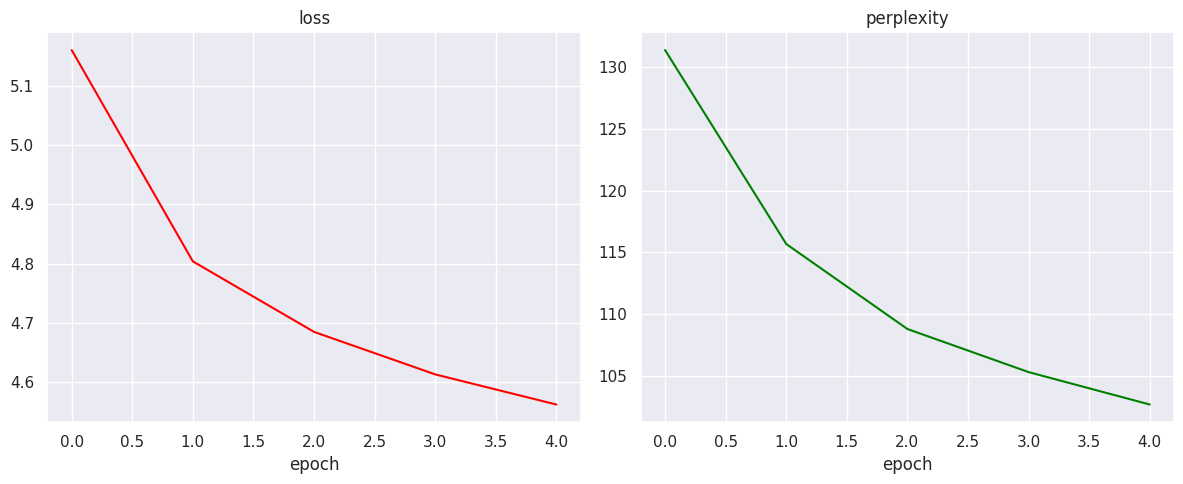

In [22]:
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
ax1.plot(range(epoch), loss[0], c='r')
ax1.set_title('loss')
ax1.set_xlabel('epoch')
ax2.plot(range(epoch), loss[1], c='g')
ax2.set_title('perplexity')
ax2.set_xlabel('epoch')

plt.tight_layout()

plt.show()

### Второй эксперимент (2 балла)

Попробуйте что-то поменять в модели или в пайплайне обучения, идеи для экспериментов можно подсмотреть выше.

In [23]:
# добавила второй линейный слой + замена Adam на AdamW
class SecondModel(nn.Module):
    def __init__(self,hidden_dim: int, vocab_size: int, num_layers: int = 1, dropout_rate: int = 0.1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.gru = nn.GRU(hidden_dim, hidden_dim, batch_first = True, num_layers=num_layers)
        self.linear1 = nn.Linear(hidden_dim, hidden_dim*2)
        self.linear2 = nn.Linear(hidden_dim*2, hidden_dim)
        self.projection = nn.Linear(hidden_dim, vocab_size)
        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=dropout_rate)

    def forward(self, input_batch: torch.Tensor) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.gru(self.dropout(embeddings))
        output = self.dropout(self.linear1(self.non_lin(output)))
        output = self.dropout(self.linear2(self.non_lin(output)))
        prediction = self.projection(output)
        return prediction

In [24]:
gc.collect()
torch.cuda.empty_cache()
epoch = 5
model = SecondModel(hidden_dim = 128, vocab_size = len(vocab)).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, betas=(0.9, 0.99), weight_decay=0.1)
loss_2 = train_model(epochs=epoch)

Training epoch: 0:   0%|          | 0/13553 [00:00<?, ?it/s]

Training epoch: 1:   0%|          | 0/13553 [00:00<?, ?it/s]

Training epoch: 2:   0%|          | 0/13553 [00:00<?, ?it/s]

Training epoch: 3:   0%|          | 0/13553 [00:00<?, ?it/s]

Training epoch: 4:   0%|          | 0/13553 [00:00<?, ?it/s]

In [25]:
losses.append(loss_2)
loss_2

([5.504482803191328,
  5.222448318847069,
  5.109560390754722,
  5.029906403171368,
  4.968825799710089],
 [190.5930153185639,
  166.1078818307162,
  152.7152547740655,
  143.52438501228625,
  137.12709546159502])

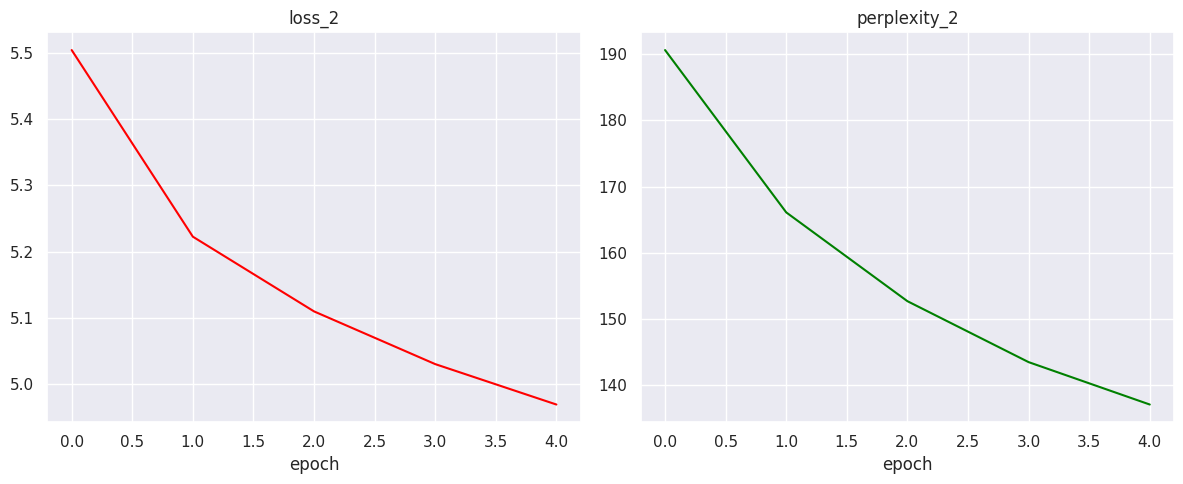

In [26]:
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
ax1.plot(range(epoch), loss_2[0], c='r')
ax1.set_title('loss_2')
ax1.set_xlabel('epoch')
ax2.plot(range(epoch), loss_2[1], c='g')
ax2.set_title('perplexity_2')
ax2.set_xlabel('epoch')

plt.tight_layout()

plt.show()

In [27]:
# 3 эксперимент, добавление LayerNorm после gru + num_layers=2

class ThirdModel(nn.Module):
    def __init__(self, hidden_dim: int, vocab_size: int, num_layers: int = 2, dropout_rate: float = 0.1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.gru = nn.GRU(hidden_dim, hidden_dim, batch_first=True, num_layers=num_layers)
        self.ln = nn.LayerNorm(hidden_dim)
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, vocab_size)
        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=dropout_rate)
        # Опишите свою нейронную сеть здесь

    def forward(self, input_batch: torch.Tensor) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.gru(self.dropout(embeddings))
        output = self.ln(output)
        output = self.dropout(self.linear(self.non_lin(output)))
        prediction = self.projection(output)
        # А тут опишите forward pass модели

        return prediction


In [28]:
gc.collect()
torch.cuda.empty_cache()
model = ThirdModel(hidden_dim=128, vocab_size=len(vocab), num_layers = 2).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, betas=(0.9, 0.99), weight_decay=0.1)
loss_3 = train_model()

Training epoch: 0:   0%|          | 0/13553 [00:00<?, ?it/s]

Training epoch: 1:   0%|          | 0/13553 [00:00<?, ?it/s]

Training epoch: 2:   0%|          | 0/13553 [00:00<?, ?it/s]

Training epoch: 3:   0%|          | 0/13553 [00:00<?, ?it/s]

Training epoch: 4:   0%|          | 0/13553 [00:00<?, ?it/s]

In [29]:
losses.append(loss_3)
loss_3

([5.4586019178233025,
  5.165746318047613,
  5.047260159066284,
  4.961036286775911,
  4.897021329773226],
 [182.56024230686964,
  159.01521141479853,
  144.6630818234784,
  135.2973063421109,
  129.31966763161628])

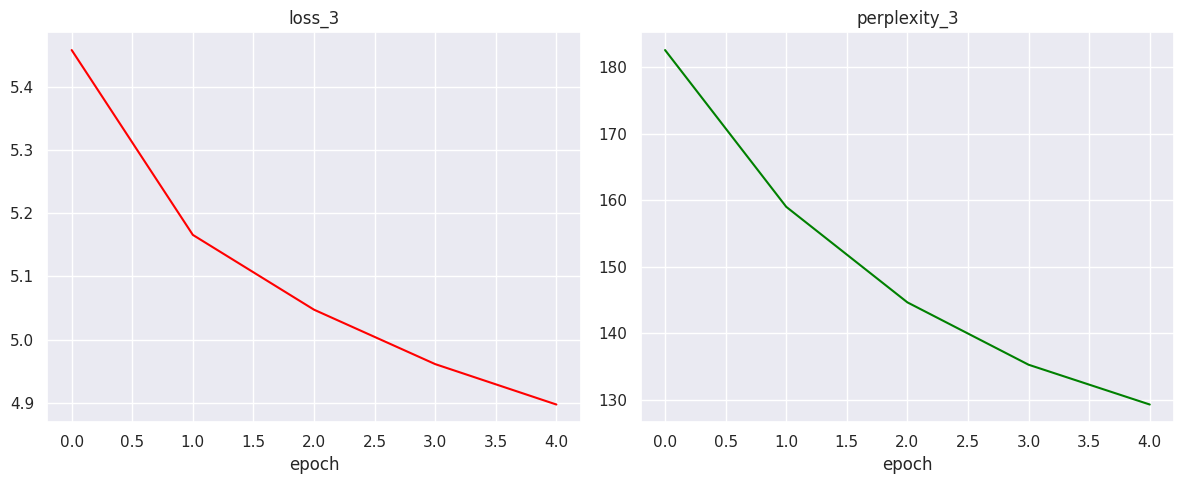

In [30]:
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
ax1.plot(range(epoch), loss_3[0], c='r')
ax1.set_title('loss_3')
ax1.set_xlabel('epoch')
ax2.plot(range(epoch), loss_3[1], c='g')
ax2.set_title('perplexity_3')
ax2.set_xlabel('epoch')

plt.tight_layout()

plt.show()

### Отчет (2 балла)

Опишите проведенные эксперименты. Сравните перплексии полученных моделей. Предложите идеи по улучшению качества моделей.

    Были проведены 3 эксперимента:
1. Базовая модель, в ней были применены стандартные практики (gru, линейный слой, tanh(), dropout), результат не совсем плохой, в сравнении с двумя последующими моделями, но немного ниже.
2. Вторая модель уже содержала 2 линейных слоя + AdamW в качестве оптимизатора. Как итог стало хуже по метрикам(больше влияния оказало 2 лин слоя)
3. Третья модель уже имела в арсенале двухслойную gru + LayerNorm после него. Именно она показала лучший результат.

    Идеи по улучшению:
1) увеличение количества эпох (метрики все еще падали, без каких-либо скачков)
2) добавление еще одного слоя gru (тк добавление 1 слоя дало буст)
3) изменение токенизатора + изменение параметра вхождения в словарь слова (количество встречаемости минимальное поднять/понизить)